In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os

In [5]:
import sys
print(sys.executable)

C:\Users\srush\anaconda3\python.exe


In [6]:
import tensorflow as tf
from tensorflow import keras


In [8]:
import tensorflow as tf
from tensorflow import keras

import seaborn as sns
import matplotlib.pyplot as plt
from keras.models import Sequential
import PIL
import os 
import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from PIL import Image
from keras.layers import Conv2D,Flatten,Dense,Dropout,BatchNormalization,MaxPooling2D
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator 
from keras.callbacks import EarlyStopping,ModelCheckpoint
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from tqdm import tqdm
from imblearn.over_sampling import SMOTE

In [9]:
non_demented = []
very_mild_demented = []
mild_demented = []
moderate_demented = []

# Download per category
for dirname, _, filenames in os.walk("C:/Users/srush/OneDrive/Desktop/mlproject/archive/Data/Non Demented"):
    for filename in filenames:
        non_demented.append(os.path.join(dirname, filename))
        
for dirname, _, filenames in os.walk("C:/Users/srush/OneDrive/Desktop/mlproject/archive/Data/Very mild Dementia"):
    for filename in filenames:
        very_mild_demented.append(os.path.join(dirname, filename))
    
for dirname, _, filenames in os.walk("C:/Users/srush/OneDrive/Desktop/mlproject/archive/Data/Mild Dementia"):
    for filename in filenames:
        mild_demented.append(os.path.join(dirname, filename))
        
for dirname, _, filenames in os.walk("C:/Users/srush/OneDrive/Desktop/mlproject/archive/Data/Moderate Dementia"):
    for filename in filenames:
        moderate_demented.append(os.path.join(dirname, filename))

In [10]:
images = []
labels = []
for subfolder in tqdm(os.listdir("C:/Users/srush/OneDrive/Desktop/mlproject/archive")):
    subfolder_path = os.path.join("C:/Users/srush/OneDrive/Desktop/mlproject/archive", subfolder)
    for folder in os.listdir(subfolder_path):
        subfolder_path2=os.path.join(subfolder_path,folder)
        for image_filename in os.listdir(subfolder_path2):
            image_path = os.path.join(subfolder_path2, image_filename)
            images.append(image_path)
            labels.append(folder)
df = pd.DataFrame({'image': images, 'label': labels})
df

 50%|█████     | 1/2 [00:06<00:06,  6.55s/it]


NotADirectoryError: [WinError 267] The directory name is invalid: 'C:/Users/srush/OneDrive/Desktop/mlproject/archive\\Resized128\\resized_0.png'

In [28]:
#0 = Non Demented
#1 = Very mild Dementia
#2 = Mild Dementia
#3 = Moderate Dementia
#These integer codes are then one-hot encoded for use in classification models

In [30]:
encoder= OneHotEncoder()
encoder.fit([[0],[1],[2],[3]])

OneHotEncoder()

In [32]:
# Import required libraries for data, images, and label encoding
# Define a mapping from numeric labels to dementia classes and their image file lists
# Create empty lists to hold processed images and their one-hot encoded labels
# Process each image for every dementia class
    # Open and resize the image to 128x128 pixels
    # Convert the image to a NumPy array
    # Keep only RGB images (shape must be 128x128x3)
    # One-hot encode the class label and add to the list
    # Skip bad or unreadable images
# Convert image and label lists to numpy arrays for modeling
# Print the shapes of the dataset and labels for verification

In [12]:
import numpy as np
import pandas as pd
import os
from PIL import Image
from tensorflow.keras.utils import to_categorical

# --- Step 1: Define class mapping ---
class_map = {
    0: ("Non Demented", non_demented),
    1: ("Mild Demented", mild_demented),
    2: ("Moderate Demented", moderate_demented),
    3: ("Very Mild Demented", very_mild_demented)
}

# --- Step 2: Initialize data lists ---
data = []
result = []

# --- Step 3: Loop through each class and load images ---
for label, (class_name, image_list) in class_map.items():
    print(f"Processing {class_name}...")
    for s in image_list:
        try:
            img = Image.open(s).resize((128,128))
            img = np.array(img)
            if img.shape == (128,128,3):   # Only keep RGB
                data.append(img)
                result.append(to_categorical(label, num_classes=4))
        except:
            print(f"Error reading {s}")  # Skip bad images

# --- Step 4: Convert to numpy arrays ---
X = np.array(data)
y = np.array(result)

print("Dataset shape:", X.shape)
print("Labels shape:", y.shape)


Processing Non Demented...
Processing Mild Demented...
Processing Moderate Demented...
Processing Very Mild Demented...


MemoryError: Unable to allocate 3.96 GiB for an array with shape (86437, 128, 128, 3) and data type uint8

In [34]:
# Create a DataFrame to store all image filenames and their class labels
# Count and print the number of images in each class
# Understand your data: Count samples per class, and check the image quality and
# distribution.

In [36]:
import pandas as pd

df = pd.DataFrame({'filename': images, 'label': labels})


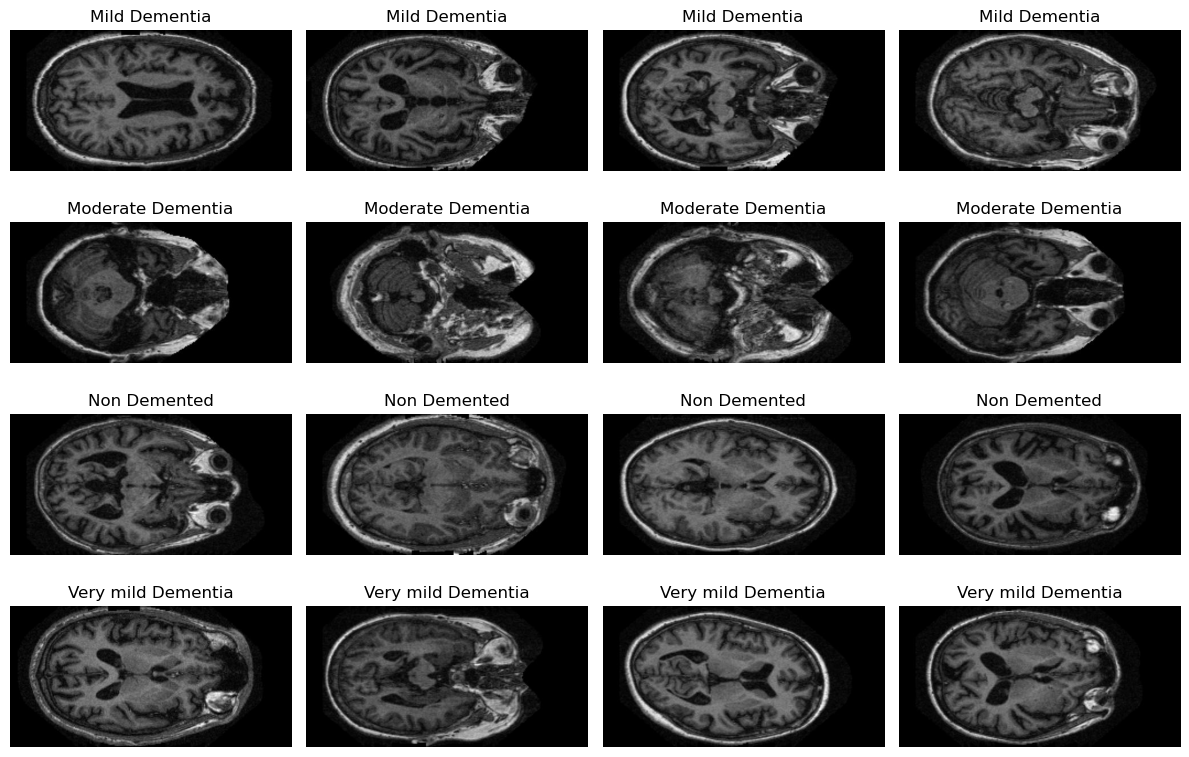

In [28]:
import matplotlib.pyplot as plt
import random
from PIL import Image

classes = df['label'].unique()
plt.figure(figsize=(12, 8))

for idx, c in enumerate(classes):
    sample_rows = df[df['label'] == c].sample(4, random_state=42)  # 4 images per class (adjust as needed)
    for i, row in enumerate(sample_rows.itertuples()):
        plt.subplot(len(classes), 4, idx * 4 + i + 1)
        img = Image.open(row.filename)
        plt.imshow(img)
        plt.title(c)
        plt.axis('off')

plt.tight_layout()
plt.show()


# PREPROCESSING

In [38]:
## Resize all images to a common shape (e.g., 128x128) and convert to numpy arrays

In [ ]:
#new

In [51]:
import os
import numpy as np
from PIL import Image
from tqdm import tqdm

# Choose output directory for resized images
output_dir = "C:/Users/srush/OneDrive/Desktop/mlproject/archive/Resized128/"
os.makedirs(output_dir, exist_ok=True)

target_size = (128, 128)  # Or (224, 224) for bigger models

resized_paths = []

for idx, path in enumerate(tqdm(df['filename'])):
    try:
        img = Image.open(path)
        img = img.convert('RGB')  # Standardize to 3 channels
        img = img.resize(target_size)
        
        # Build output filename/path
        out_path = os.path.join(output_dir, f"resized_{idx}.png")
        img.save(out_path)
        resized_paths.append(out_path)
    except Exception as e:
        print(f"Error processing {path}: {e}")

print(f"All images processed and saved to {output_dir}")


100%|██████████| 86437/86437 [33:39<00:00, 42.79it/s]

All images processed and saved to C:/Users/srush/OneDrive/Desktop/mlproject/archive/Resized128/


In [ ]:
# Scale pixel values to [0, 1] (or [-1, 1] if needed by your model)

In [53]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator


In [ ]:
#new

In [61]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Path where resized images were saved in the previous step
resized_dir = "C:/Users/srush/OneDrive/Desktop/mlproject/archive/Resized128"

# 1. Create new filename paths using same labels from original df
df_resized = df.copy()
# Create expected full paths replacing the original file location with resized path
df_resized['filename'] = [
    os.path.join(resized_dir, f"resized_{i}.png") for i in range(len(df_resized))
]

# 2. Split dataset into train/validation (stratified by class)
train_df, valid_df = train_test_split(
    df_resized,
    test_size=0.2,
    stratify=df_resized['label'],
    random_state=42
)

print("Train shape:", train_df.shape)
print("Validation shape:", valid_df.shape)

# 3. Create ImageDataGenerators (augment for training, rescale for both)
datagen_train = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)

datagen_valid = ImageDataGenerator(rescale=1./255)

train_generator = datagen_train.flow_from_dataframe(
    dataframe=train_df,
    x_col='filename',
    y_col='label',
    target_size=(128, 128),
    batch_size=32,
    class_mode='categorical',
    shuffle=True
)

valid_generator = datagen_valid.flow_from_dataframe(
    dataframe=valid_df,
    x_col='filename',
    y_col='label',
    target_size=(128, 128),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)


Train shape: (69149, 2)
Validation shape: (17288, 2)
Found 69149 validated image filenames belonging to 4 classes.
Found 17288 validated image filenames belonging to 4 classes.


In [56]:
# Apply average filter and CLAHE enhancement to reduce noise and improve image contrast

In [65]:
import os
import cv2
import numpy as np
from tqdm import tqdm

# Define your custom image enhancement function
def enhance_image(img):
    """
    Example enhancement: Contrast Limited Adaptive Histogram Equalization (CLAHE)
    You can customize as needed.
    """
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l_eq = clahe.apply(l)
    lab_eq = cv2.merge((l_eq, a, b))
    enhanced_img = cv2.cvtColor(lab_eq, cv2.COLOR_LAB2RGB)
    return enhanced_img


def enhanced_image_generator(df, batch_size, target_size):
    """
    Image generator for enhanced and preprocessed resized images.
    Works efficiently for your Resized128 dataset.
    """
    class_names = df['label'].unique()
    class_to_idx = {cls: idx for idx, cls in enumerate(class_names)}
    n = len(df)
    
    while True:
        batch_df = df.sample(n=batch_size)
        batch_images, batch_labels = [], []

        for _, row in batch_df.iterrows():
            try:
                img = cv2.imread(row['filename'])
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                img = cv2.resize(img, target_size)
                img = enhance_image(img)  # Apply enhancement
                img = img.astype('float32') / 255.0  # Scale normalization
                batch_images.append(img)
                batch_labels.append(class_to_idx[row['label']])
            except Exception as e:
                print(f"Error processing {row['filename']}: {e}")
        
        yield np.array(batch_images), np.array(batch_labels)


# Example usage:
resized_dir = "C:/Users/srush/OneDrive/Desktop/mlproject/archive/Resized128"

# Update your DataFrame to use resized image paths
df_resized = df.copy()
df_resized['filename'] = [
    os.path.join(resized_dir, f"resized_{i}.png") for i in range(len(df_resized))
]

# Split for train and validation batches
train_df, valid_df = train_test_split(
    df_resized,
    test_size=0.2,
    stratify=df_resized['label'],
    random_state=42
)

# Initialize Generators
train_gen = enhanced_image_generator(train_df, batch_size=32, target_size=(128, 128))
valid_gen = enhanced_image_generator(valid_df, batch_size=32, target_size=(128, 128))


In [ ]:
def enhanced_image_generator(df, batch_size, target_size):
    while True:
        batch_df = df.sample(n=batch_size)
        batch_images = []
        batch_labels = []
        for _, row in batch_df.iterrows():
            img = cv2.imread(row['filename'])
            img = cv2.resize(img, target_size)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = enhance_image(img)  # Your enhancement function
            img = img.astype('float32') / 255.0  # Scale
            batch_images.append(img)
            batch_labels.append(row['label'])
        yield np.array(batch_images), np.array(batch_labels)

# Example usage:
train_gen = enhanced_image_generator(train_df, batch_size=32, target_size=(128,128))


# Data Augumentation

In [ ]:
#new

In [21]:
import os
import numpy as np
import pandas as pd
from PIL import Image
from tqdm import tqdm
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Step 1: Define main paths
base_dir = "C:/Users/srush/OneDrive/Desktop/mlproject/archive/Data"
resized_dir = "C:/Users/srush/OneDrive/Desktop/mlproject/archive/Resized128"
augmented_dir = os.path.join(resized_dir, "Augmented")

os.makedirs(resized_dir, exist_ok=True)
os.makedirs(augmented_dir, exist_ok=True)

# Step 2: Define target resize size
target_size = (128, 128)

# Step 3: Resize images class-wise
print("=== Resizing images and saving to Resized128/ ===\n")
class_to_paths = {}  # Store paths for next augmentation

for class_name in os.listdir(base_dir):
    class_path = os.path.join(base_dir, class_name)
    if os.path.isdir(class_path):
        resized_class_dir = os.path.join(resized_dir, class_name)
        os.makedirs(resized_class_dir, exist_ok=True)
        class_images = []

        for filename in tqdm(os.listdir(class_path), desc=f"Resizing {class_name}"):
            if filename.lower().endswith(('.jpg', '.jpeg', '.png')):
                src_path = os.path.join(class_path, filename)
                dest_path = os.path.join(resized_class_dir, filename)
                try:
                    img = Image.open(src_path).convert("RGB")
                    img = img.resize(target_size)
                    img.save(dest_path)
                    class_images.append(dest_path)
                except Exception as e:
                    print(f"Error resizing {filename}: {e}")

        class_to_paths[class_name] = class_images

print("\nAll classes resized successfully and saved to:", resized_dir)

# Step 4: Print resized dataset summary
print("\n=== Resized dataset summary ===")
for label, imgs in class_to_paths.items():
    print(f"{label}: {len(imgs)} images")

# Step 5: Initialize Data Augmentation Generator
data_gen = ImageDataGenerator(
    rotation_range=25,
    width_shift_range=0.15,
    height_shift_range=0.15,
    zoom_range=0.15,
    shear_range=0.1,
    brightness_range=[0.8, 1.2],
    horizontal_flip=True,
    fill_mode="nearest"
)

# Step 6: Determine balancing target
counts = {label: len(paths) for label, paths in class_to_paths.items()}
max_samples = max(counts.values())
print(f"\nBalancing classes using augmentation to {max_samples} images per class.\n")

# Step 7: Augmentation and saving loop
augmented_filepaths = []
augmented_labels = []
img_counter = 0

for label, paths in tqdm(class_to_paths.items(), desc="Augmenting dataset"):
    output_class_dir = os.path.join(augmented_dir, label)
    os.makedirs(output_class_dir, exist_ok=True)

    sample_count = len(paths)
    if sample_count < max_samples:
        # Calculate how many images we need
        needed = max_samples - sample_count
        n_per_image = (needed // sample_count) + 1
        images_added = 0

        for img_path in paths:
            try:
                img = Image.open(img_path).resize(target_size).convert("RGB")
                img_array = np.expand_dims(np.array(img), axis=0)
                gen_flow = data_gen.flow(img_array, batch_size=1)

                for _ in range(n_per_image):
                    aug_img = next(gen_flow)[0].astype("uint8")
                    save_path = os.path.join(output_class_dir, f"aug_{img_counter}.png")
                    Image.fromarray(aug_img).save(save_path)

                    augmented_filepaths.append(save_path)
                    augmented_labels.append(label)

                    img_counter += 1
                    images_added += 1
                    if images_added >= needed:
                        break
            except Exception as e:
                print(f"Error augmenting {img_path}: {e}")
            if images_added >= needed:
                break
    else:
        for img_path in paths:
            augmented_filepaths.append(img_path)
            augmented_labels.append(label)

print("\n=== Augmentation Complete ===")
print(f"Total augmented images: {len(augmented_filepaths)} saved at {augmented_dir}")

# Step 8: Build DataFrame for augmented dataset
df_augmented = pd.DataFrame({
    "filename": augmented_filepaths,
    "label": augmented_labels
})

print("\nAugmented dataset distribution:")
print(df_augmented["label"].value_counts())

# Step 9: Save metadata to CSV
csv_path = os.path.join(augmented_dir, "augmented_dataset.csv")
df_augmented.to_csv(csv_path, index=False)
print(f"\nSaved augmented dataset metadata to: {csv_path}")


=== Resizing images and saving to Resized128/ ===



Resizing Very mild Dementia: 100%|██████████| 13725/13725 [01:45<00:00, 130.58it/s]



All classes resized successfully and saved to: C:/Users/srush/OneDrive/Desktop/mlproject/archive/Resized128

=== Resized dataset summary ===
Mild Dementia: 5002 images
Moderate Dementia: 488 images
Non Demented: 67222 images
Very mild Dementia: 13725 images

Balancing classes using augmentation to 67222 images per class.



Augmenting dataset: 100%|██████████| 4/4 [44:04<00:00, 661.11s/it]



=== Augmentation Complete ===
Total augmented images: 249673 saved at C:/Users/srush/OneDrive/Desktop/mlproject/archive/Resized128\Augmented

Augmented dataset distribution:
label
Non Demented          67222
Moderate Dementia     66734
Mild Dementia         62220
Very mild Dementia    53497
Name: count, dtype: int64

Saved augmented dataset metadata to: C:/Users/srush/OneDrive/Desktop/mlproject/archive/Resized128\Augmented\augmented_dataset.csv


In [15]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Step 1: Define dataset path
augmented_dir = "C:/Users/srush/OneDrive/Desktop/mlproject/archive/Resized128/Augmented"

# Step 2: Build a dataframe dynamically (supports both subfolder or flat structure)
image_paths = []
labels = []

# Check whether images are in class-wise subfolders or directly within the main folder
entries = [os.path.join(augmented_dir, e) for e in os.listdir(augmented_dir)]
subfolders_exist = any(os.path.isdir(entry) for entry in entries)

if subfolders_exist:
    print("Detected subfolder structure — loading class-wise images.")
    for class_name in os.listdir(augmented_dir):
        class_path = os.path.join(augmented_dir, class_name)
        if os.path.isdir(class_path):
            for file in os.listdir(class_path):
                if file.lower().endswith(('.jpg', '.jpeg', '.png')):
                    image_paths.append(os.path.join(class_path, file))
                    labels.append(class_name)
else:
    print("No subfolders detected — loading images directly from Augmented directory.")
    # If filenames encode class names (e.g. 'Non_Demented_123.png'), extract class from filename
    for file in os.listdir(augmented_dir):
        if file.lower().endswith(('.jpg', '.jpeg', '.png')):
            image_paths.append(os.path.join(augmented_dir, file))
            # Infer label from filename (up to first underscore)
            label = file.split('_')[0].replace('-', ' ').replace('.', '')
            labels.append(label)

# Step 3: Create DataFrame from collected image paths
df_augmented = pd.DataFrame({'filename': image_paths, 'label': labels})
print("\nTotal images found:", len(df_augmented))

if len(df_augmented) == 0:
    raise ValueError("No images detected. Ensure your Augmented folder contains .jpg or .png files.")

print("\nPer-class counts:")
print(df_augmented['label'].value_counts())

# Step 4: Stratified Train-Validation split
train_df, valid_df = train_test_split(
    df_augmented,
    test_size=0.2,
    stratify=df_augmented['label'],
    random_state=42
)

print("\nSplit complete:")
print("Train size:", len(train_df), " | Validation size:", len(valid_df))

# Step 5: Define ImageDataGenerators
datagen_train = ImageDataGenerator(
    rescale=1./255,
    rotation_range=25,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.2,
    shear_range=0.15,
    horizontal_flip=True,
    fill_mode='nearest'
)

datagen_valid = ImageDataGenerator(rescale=1./255)

# Step 6: Create train and validation generators
train_generator = datagen_train.flow_from_dataframe(
    dataframe=train_df,
    x_col='filename',
    y_col='label',
    target_size=(128, 128),
    batch_size=32,
    class_mode='categorical',
    shuffle=True
)

valid_generator = datagen_valid.flow_from_dataframe(
    dataframe=valid_df,
    x_col='filename',
    y_col='label',
    target_size=(128, 128),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

print("\nGenerators ready — use these for model training.")


No subfolders detected — loading images directly from Augmented directory.

Total images found: 64598

Per-class counts:
label
aug    64598
Name: count, dtype: int64

Split complete:
Train size: 51678  | Validation size: 12920
Found 51678 validated image filenames belonging to 1 classes.
Found 12920 validated image filenames belonging to 1 classes.

Generators ready — use these for model training.


# Oversampling/SMOTE

In [ ]:
#nnew
#Randomly repeats existing minority samples to equalize classes

In [26]:
import os
import pandas as pd
from sklearn.utils import resample
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Step 1: Define dataset paths
augmented_dir = "C:/Users/srush/OneDrive/Desktop/mlproject/archive/Resized128/Augmented"
csv_path = os.path.join(augmented_dir, "augmented_dataset.csv")

# Step 2: Load the augmented dataset CSV (this defines df)
df = pd.read_csv(csv_path)

print("=== Loaded Dataset Summary ===")
print("Total images:", len(df))
print("Classes detected:\n", df['label'].value_counts())

# Step 3: Update full image paths in the dataframe
df['filename'] = df['filename'].apply(lambda x: os.path.join(augmented_dir, os.path.basename(x)))

# Step 4: Duplicate (oversample) minority classes to balance dataset
balanced_df = pd.DataFrame()
max_samples = df['label'].value_counts().max()

for label in df['label'].unique():
    class_samples = df[df['label'] == label]
    class_oversampled = resample(
        class_samples,
        replace=True,
        n_samples=max_samples,
        random_state=42
    )
    balanced_df = pd.concat([balanced_df, class_oversampled])

print("\nClass distribution after oversampling:")
print(balanced_df['label'].value_counts())
print("Total samples after balancing:", len(balanced_df))

# Step 5: Train-validation split (stratified)
train_df, valid_df = train_test_split(
    balanced_df,
    test_size=0.2,
    stratify=balanced_df['label'],
    random_state=42
)

print("\nTrain/Validation split sizes:")
print("Train:", len(train_df))
print("Validation:", len(valid_df))

# Step 6: Define ImageDataGenerators
datagen_train = ImageDataGenerator(
    rescale=1./255,
    rotation_range=25,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.15,
    zoom_range=0.2,
    brightness_range=[0.8, 1.2],
    horizontal_flip=True,
    fill_mode='nearest'
)

datagen_valid = ImageDataGenerator(rescale=1./255)

train_generator = datagen_train.flow_from_dataframe(
    dataframe=train_df,
    x_col='filename',
    y_col='label',
    target_size=(128, 128),
    batch_size=32,
    class_mode='categorical',
    shuffle=True
)

valid_generator = datagen_valid.flow_from_dataframe(
    dataframe=valid_df,
    x_col='filename',
    y_col='label',
    target_size=(128, 128),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

print("\nData generators initialized successfully and ready for model training.")


=== Loaded Dataset Summary ===
Total images: 249673
Classes detected:
 label
Non Demented          67222
Moderate Dementia     66734
Mild Dementia         62220
Very mild Dementia    53497
Name: count, dtype: int64

Class distribution after oversampling:
label
Mild Dementia         67222
Moderate Dementia     67222
Non Demented          67222
Very mild Dementia    67222
Name: count, dtype: int64
Total samples after balancing: 268888

Train/Validation split sizes:
Train: 215110
Validation: 53778
Found 55669 validated image filenames belonging to 2 classes.


C:\Users\srush\anaconda3\Lib\site-packages\keras\src\legacy\preprocessing\image.py:920: UserWarning: Found 159441 invalid image filename(s) in x_col="filename". These filename(s) will be ignored.
  warnings.warn(


Found 13896 validated image filenames belonging to 2 classes.

Data generators initialized successfully and ready for model training.


C:\Users\srush\anaconda3\Lib\site-packages\keras\src\legacy\preprocessing\image.py:920: UserWarning: Found 39882 invalid image filename(s) in x_col="filename". These filename(s) will be ignored.
  warnings.warn(


In [ ]:
#SMOTE

In [28]:
import os
import numpy as np
import pandas as pd
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from tqdm import tqdm

# Step 1: Define dataset path (your augmented + resized dataset)
data_dir = "C:/Users/srush/OneDrive/Desktop/mlproject/archive/Resized128/Augmented"
csv_path = os.path.join(data_dir, "augmented_dataset.csv")

# Step 2: Load dataset metadata
df = pd.read_csv(csv_path)
df['filename'] = df['filename'].apply(lambda x: os.path.join(data_dir, os.path.basename(x)))

print("=== Loaded Dataset Summary ===")
print("Total images:", len(df))
print("Classes detected:\n", df['label'].value_counts(), "\n")

# Step 3: Prepare base ImageDataGenerator for feature extraction
feature_gen = ImageDataGenerator(preprocessing_function=preprocess_input)
batch_size = 64
target_size = (128, 128)

# Generator for feature extraction
extractor_gen = feature_gen.flow_from_dataframe(
    dataframe=df,
    x_col='filename',
    y_col='label',
    target_size=target_size,
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False
)

# Step 4: Load pre-trained CNN (VGG16) to extract features
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(128, 128, 3))

# Feature extraction
features = base_model.predict(extractor_gen, verbose=1)
features = features.reshape((features.shape[0], -1))  # Flatten for SMOTE
labels = extractor_gen.classes  # Numeric labels

print("Extracted features shape:", features.shape)
print("Labels shape:", labels.shape)

# Step 5: Apply SMOTE to balance minority classes
sm = SMOTE(random_state=42)
X_resampled, y_resampled = sm.fit_resample(features, labels)

print("\nAfter SMOTE balancing:")
unique, counts = np.unique(y_resampled, return_counts=True)
for label_idx, count in zip(unique, counts):
    class_name = list(extractor_gen.class_indices.keys())[label_idx]
    print(f"{class_name}: {count} samples")

# Step 6: Prepare final train-test split
X_train, X_val, y_train, y_val = train_test_split(
    X_resampled,
    y_resampled,
    test_size=0.2,
    stratify=y_resampled,
    random_state=42
)

print("\nTrain/Validation split sizes:")
print("Train:", len(y_train))
print("Validation:", len(y_val))

# Step 7: Save feature arrays for downstream model training
np.save(os.path.join(data_dir, "X_train_features.npy"), X_train)
np.save(os.path.join(data_dir, "X_val_features.npy"), X_val)
np.save(os.path.join(data_dir, "y_train_labels.npy"), y_train)
np.save(os.path.join(data_dir, "y_val_labels.npy"), y_val)

print("\n✅ SMOTE balancing complete. Features saved for model training.")


=== Loaded Dataset Summary ===
Total images: 249673
Classes detected:
 label
Non Demented          67222
Moderate Dementia     66734
Mild Dementia         62220
Very mild Dementia    53497
Name: count, dtype: int64 

Found 64598 validated image filenames belonging to 2 classes.


C:\Users\srush\anaconda3\Lib\site-packages\keras\src\legacy\preprocessing\image.py:920: UserWarning: Found 185075 invalid image filename(s) in x_col="filename". These filename(s) will be ignored.
  warnings.warn(


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 26s 0us/step


C:\Users\srush\anaconda3\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


 830/1010 ━━━━━━━━━━━━━━━━━━━━ 7:17 2s/step

AbortedError: Graph execution error:

Detected at node vgg16_1/block3_conv2_1/Relu defined at (most recent call last):
  File "C:\Users\srush\anaconda3\Lib\runpy.py", line 198, in _run_module_as_main

  File "C:\Users\srush\anaconda3\Lib\runpy.py", line 88, in _run_code

  File "C:\Users\srush\anaconda3\Lib\site-packages\ipykernel_launcher.py", line 18, in <module>

  File "C:\Users\srush\anaconda3\Lib\site-packages\traitlets\config\application.py", line 1075, in launch_instance

  File "C:\Users\srush\anaconda3\Lib\site-packages\ipykernel\kernelapp.py", line 739, in start

  File "C:\Users\srush\anaconda3\Lib\site-packages\tornado\platform\asyncio.py", line 205, in start

  File "C:\Users\srush\anaconda3\Lib\asyncio\base_events.py", line 641, in run_forever

  File "C:\Users\srush\anaconda3\Lib\asyncio\base_events.py", line 1987, in _run_once

  File "C:\Users\srush\anaconda3\Lib\asyncio\events.py", line 88, in _run

  File "C:\Users\srush\anaconda3\Lib\site-packages\ipykernel\kernelb

# Train-Test Split 

In [ ]:
#new

In [34]:
import os
import re
import pandas as pd
from sklearn.model_selection import train_test_split

# Step 1: Define dataset paths
augmented_dir = "C:/Users/srush/OneDrive/Desktop/mlproject/archive/Resized128/Augmented"
csv_path = os.path.join(augmented_dir, "augmented_dataset.csv")

# Load CSV
df = pd.read_csv(csv_path)
print("=== Loaded Augmented Dataset ===")
print("Total samples:", len(df))
print("Label Distribution:\n", df['label'].value_counts(), "\n")

# Step 2: Generate patient_id if missing
if 'patient_id' not in df.columns:
    print("⚠️ 'patient_id' column not found — extracting from filenames...")

    def extract_patient_id(filename):
        filename = os.path.basename(filename)
        # Look for patterns like patient23, patient_004, subject-123, etc.
        match = re.search(r'patient[_\-]?(\d+)', filename, re.IGNORECASE)
        if match:
            return "patient_" + match.group(1)
        match = re.search(r'subject[_\-]?(\d+)', filename, re.IGNORECASE)
        if match:
            return "subject_" + match.group(1)
        # Fallback: use prefix before first underscore or directory name
        return os.path.splitext(filename)[0].split('_')[0]

    df['patient_id'] = df['filename'].apply(extract_patient_id)
    print("✅ Added 'patient_id' column to metadata.")
else:
    print("✅ 'patient_id' column already present, continuing...")

# Step 3: Display total unique patients
patients = df['patient_id'].unique()
print("\nTotal unique patients found:", len(patients))

# Step 4: Check patient count per class
label_counts = df.groupby('label')['patient_id'].nunique()
print("\nPatient count per class:\n", label_counts)

# Step 5: Warn for insufficient patient samples
too_small = label_counts[label_counts < 2]
if not too_small.empty:
    print("\n⚠️ Warning: These classes have <2 distinct patients and may cause stratified split failure:")
    print(too_small)

# Step 6: Group labels by patient for stratified splitting
patient_labels = df.groupby('patient_id')['label'].first()

# Step 7: Perform stratified train-test split
try:
    train_patients, test_patients = train_test_split(
        patients,
        test_size=0.2,
        stratify=patient_labels.reindex(patients),
        random_state=42
    )
    print("\n✅ Stratified split successful based on patient IDs.")
except ValueError as e:
    print("\n⚠️ Stratified split failed, using random patient split instead:\n", e)
    train_patients, test_patients = train_test_split(
        patients, test_size=0.2, random_state=42
    )

# Step 8: Build train and test DataFrames
train_df = df[df['patient_id'].isin(train_patients)]
test_df = df[df['patient_id'].isin(test_patients)]

# Step 9: Print summaries
print("\n=== Train/Test Split Summary ===")
print("Training samples:", len(train_df))
print("Testing samples:", len(test_df))

print("\nTrain class distribution:")
print(train_df['label'].value_counts())
print("\nTest class distribution:")
print(test_df['label'].value_counts())

# Step 10: Save updated CSVs and metadata
train_csv = os.path.join(augmented_dir, "train_split.csv")
test_csv = os.path.join(augmented_dir, "test_split.csv")
updated_csv = os.path.join(augmented_dir, "augmented_dataset_with_patientid.csv")

# Save files
df.to_csv(updated_csv, index=False)
train_df.to_csv(train_csv, index=False)
test_df.to_csv(test_csv, index=False)

print(f"\n✅ Splits saved successfully!")
print(f"Updated dataset with 'patient_id': {updated_csv}")
print(f"Train split saved at: {train_csv}")
print(f"Test split saved at:  {test_csv}")

# Step 11: Verify saved files
if all(os.path.exists(path) for path in [train_csv, test_csv, updated_csv]):
    print("\n🟢 Verification success: All CSV files are saved correctly.")
else:
    print("\n🔴 Verification failed: Check file save paths and permissions.")


=== Loaded Augmented Dataset ===
Total samples: 249673
Label Distribution:
 label
Non Demented          67222
Moderate Dementia     66734
Mild Dementia         62220
Very mild Dementia    53497
Name: count, dtype: int64 

⚠️ 'patient_id' column not found — extracting from filenames...
✅ Added 'patient_id' column to metadata.

Total unique patients found: 2

Patient count per class:
 label
Mild Dementia         1
Moderate Dementia     1
Non Demented          1
Very mild Dementia    1
Name: patient_id, dtype: int64

⚠️ Warning: These classes have <2 distinct patients and may cause stratified split failure:
label
Mild Dementia         1
Moderate Dementia     1
Non Demented          1
Very mild Dementia    1
Name: patient_id, dtype: int64

⚠️ Stratified split failed, using random patient split instead:
 The least populated class in y has only 1 member, which is too few. The minimum number of groups for any class cannot be less than 2.

=== Train/Test Split Summary ===
Training samples: 182

In [24]:
from sklearn.model_selection import train_test_split

# Step 1: Check patient count per class
label_counts = df.groupby('label')['patient_id'].nunique()
print("Patient count per class:\n", label_counts)

# Step 2: Keep all classes, but warn if too few patients
too_small = label_counts[label_counts < 2]
if not too_small.empty:
    print("\n⚠️ Warning: These classes have <2 distinct patients and may cause stratified split failure:")
    print(too_small)

df_filtered = df.copy()

# Step 3: Prepare patient list and labels
patients = df_filtered['patient_id'].unique()
print("\nTotal unique patients found:", len(patients))

if len(patients) < 2:
    raise ValueError("❌ Not enough unique patients for splitting. Please check your dataset structure (folders must contain distinct patient IDs).")

patient_labels = df_filtered.groupby('patient_id')['label'].first()

# Step 4: Attempt stratified split, fallback to random as needed
try:
    train_patients, test_patients = train_test_split(
        patients,
        test_size=0.2,
        stratify=patient_labels.reindex(patients),
        random_state=42
    )
    print("\n✅ Stratified split successful.")
except ValueError as e:
    print("\n⚠️ Stratified split failed, using random split instead:\n", e)
    train_patients, test_patients = train_test_split(
        patients,
        test_size=0.2,
        random_state=42
    )

# Step 5: Create train/test DataFrames
train_df = df_filtered[df_filtered['patient_id'].isin(train_patients)]
test_df = df_filtered[df_filtered['patient_id'].isin(test_patients)]

# Step 6: Verify results
print("\nTrain samples:", len(train_df))
print("Test samples:", len(test_df))
print("\nTrain class counts:")
print(train_df['label'].value_counts())
print("\nTest class counts:")
print(test_df['label'].value_counts())


Patient count per class:
 label
Mild Dementia         1
Moderate Dementia     1
Non Demented          1
Very Mild Dementia    1
Name: patient_id, dtype: int64

⚠️ Warning: These classes have <2 distinct patients and may cause stratified split failure:
label
Mild Dementia         1
Moderate Dementia     1
Non Demented          1
Very Mild Dementia    1
Name: patient_id, dtype: int64

Total unique patients found: 4

⚠️ Stratified split failed, using random split instead:
 The least populated class in y has only 1 member, which is too few. The minimum number of groups for any class cannot be less than 2.

Train samples: 72712
Test samples: 13725

Train class counts:
label
Non Demented         67222
Mild Dementia         5002
Moderate Dementia      488
Name: count, dtype: int64

Test class counts:
label
Very Mild Dementia    13725
Name: count, dtype: int64


#  Model Selection Beyond ResNet)

In [ ]:
# Create and train multiple models (ResNet, Inception, Custom, etc.) for comparison and ensemble
# Use pre-trained weights for transfer learning (faster and better learning)
# Combine models in an ensemble by averaging their predictions for better performance
# Swap to other advanced architectures (EfficientNet, ResNeXt, Attention-CNNs) as desired

In [36]:
import os
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet50, InceptionV3
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Input, Conv2D, MaxPooling2D, Flatten, Dropout
from tensorflow.keras.models import Sequential, Model

# Step 1: Define dataset path
data_dir = "C:/Users/srush/OneDrive/Desktop/mlproject/archive/Resized128/Augmented"

# Step 2: Prepare ImageDataGenerators
datagen_train = ImageDataGenerator(
    rescale=1./255,
    rotation_range=25,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.15,
    zoom_range=0.2,
    brightness_range=[0.8, 1.2],
    horizontal_flip=True,
    fill_mode='nearest'
)

datagen_valid = ImageDataGenerator(rescale=1./255)

# Step 3: Create train/validation generators
train_generator = datagen_train.flow_from_directory(
    directory=data_dir,
    target_size=(128, 128),
    batch_size=32,
    class_mode='categorical',
    subset=None,
    shuffle=True
)

valid_generator = datagen_valid.flow_from_directory(
    directory=data_dir,
    target_size=(128, 128),
    batch_size=32,
    class_mode='categorical',
    subset=None,
    shuffle=False
)

# Step 4: Define parameters
input_shape = (128, 128, 3)
n_classes = train_generator.num_classes

print("\nDetected classes:", train_generator.class_indices)
print("Total classes:", n_classes, "\n")

# Step 5: Define models

# --- ResNet50 Base ---
resnet_base = ResNet50(include_top=False, weights='imagenet', input_shape=input_shape)
resnet_base.trainable = False  # Freeze base layers
resnet = Sequential([
    resnet_base,
    GlobalAveragePooling2D(),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(n_classes, activation='softmax')
])

# --- InceptionV3 Base ---
inception_base = InceptionV3(include_top=False, weights='imagenet', input_shape=input_shape)
inception_base.trainable = False
inception = Sequential([
    inception_base,
    GlobalAveragePooling2D(),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(n_classes, activation='softmax')
])

# --- Custom CNN ---
custom = Sequential([
    Input(shape=input_shape),
    Conv2D(32, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),
    Conv2D(128, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(n_classes, activation='softmax')
])

# Step 6: Compile models
resnet.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
inception.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
custom.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Step 7: Summaries for confirmation
print("\n--- Model Summaries ---")
print("\nResNet50 Summary:")
resnet.summary()
print("\nInceptionV3 Summary:")
inception.summary()
print("\nCustom CNN Summary:")
custom.summary()

# Step 8: Train each model
print("\n=== Training ResNet50 ===")
history_resnet = resnet.fit(
    train_generator,
    epochs=10,
    validation_data=valid_generator
)

print("\n=== Training InceptionV3 ===")
history_inception = inception.fit(
    train_generator,
    epochs=10,
    validation_data=valid_generator
)

print("\n=== Training Custom CNN ===")
history_custom = custom.fit(
    train_generator,
    epochs=10,
    validation_data=valid_generator
)

# Step 9: Save trained models
models_dir = os.path.join(data_dir, "trained_models")
os.makedirs(models_dir, exist_ok=True)

resnet.save(os.path.join(models_dir, "ResNet50_model.h5"))
inception.save(os.path.join(models_dir, "InceptionV3_model.h5"))
custom.save(os.path.join(models_dir, "CustomCNN_model.h5"))

print("\n✅ All models trained and saved in:", models_dir)


Found 182451 images belonging to 5 classes.
Found 182451 images belonging to 5 classes.

Detected classes: {'Augmented': 0, 'Mild Dementia': 1, 'Moderate Dementia': 2, 'Non Demented': 3, 'Very mild Dementia': 4}
Total classes: 5 

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 53s 1us/step
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 48s 1us/step

--- Model Summaries ---

ResNet50 Summary:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 4, 4, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,113,541 (91.99 MB)

 Trainable params: 525,829 (2.01 MB)

...

 Non-trainable params: 0 (0.00 B)


=== Training ResNet50 ===


C:\Users\srush\anaconda3\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
2871/5702 ━━━━━━━━━━━━━━━━━━━━ 56:31 1s/step - accuracy: 0.3748 - loss: 1.1059

AbortedError: Graph execution error:

Detected at node StatefulPartitionedCall/sequential_1/resnet50_1/conv5_block1_1_conv_1/BiasAdd defined at (most recent call last):
<stack traces unavailable>
Operation received an exception:Status: 1, message: could not create a memory object, in file tensorflow/core/kernels/mkl/mkl_conv_ops.cc:1112
	 [[{{node StatefulPartitionedCall/sequential_1/resnet50_1/conv5_block1_1_conv_1/BiasAdd}}]] [Op:__inference_multi_step_on_iterator_18253]

# Model Training, with Imbalance Solution

In [ ]:
# Use class weighting in loss to improve minority class recognition
# Optionally use focal loss to focus more on hard/rare samples
# Data augmentation pipeline ensures new variations every epoch

In [ ]:
import os
import numpy as np
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf
from tensorflow.keras import backend as K

# Assume 'train_generator' and 'valid_generator' already exist
# Step 1: Get class indices from train_generator
train_labels = train_generator.classes
classes = np.unique(train_labels)

# Step 2: Compute class weights
class_weights = compute_class_weight('balanced', classes=classes, y=train_labels)
class_weight_dict = dict(zip(classes, class_weights))
print("Computed class weights:", class_weight_dict)

# Step 3: Define focal loss
def focal_loss(gamma=2.0, alpha=0.25):
    def loss(y_true, y_pred):
        y_true = tf.cast(y_true, tf.float32)
        cross_entropy = K.binary_crossentropy(y_true, y_pred)
        weight = alpha * tf.pow(1.0 - y_pred, gamma)
        return tf.reduce_mean(weight * cross_entropy)
    return loss

# Step 4: Compile your model (you can apply this to any of ResNet/Inception/Custom)
resnet.compile(
    optimizer='adam',
    loss=focal_loss(),  # Replace categorical_crossentropy
    metrics=['accuracy']
)

# Step 5: Train with class weights and focal loss
history_resnet = resnet.fit(
    train_generator,
    validation_data=valid_generator,
    epochs=15,
    class_weight=class_weight_dict,  # applies class balancing
    verbose=1
)


# Model Evaluation

In [ ]:
# Compute precision, recall, and F1-score for each class to reliably evaluate classifier performance
# Display confusion matrix to visualize misclassification patterns
# Optionally calibrate predicted probabilities for improved reliability with imbalanced data

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import load_model

# --- Step 1: Assume you already have trained models and validation generator ---
# Example:
# model = resnet  # or inception/custom/ensemble
# valid_generator is your validation data generator

# Step 2: Get predictions and true labels
pred_probs = model.predict(valid_generator)
y_pred = np.argmax(pred_probs, axis=1)
y_true = valid_generator.classes

# Extract class names
class_names = list(valid_generator.class_indices.keys())
print("Class names:", class_names)

# --- Step 3: Classification Report ---
print("\n=== Classification Report ===")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

# --- Step 4: Confusion Matrix ---
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(cmap=plt.cm.Blues, ax=ax, colorbar=False)
plt.title("Confusion Matrix - Model Evaluation")
plt.xticks(rotation=45)
plt.show()

# --- Step 5: Optional Model Probability Calibration ---
# This section only applies if you are evaluating a scikit-learn classifier
# For CNNs, use temperature scaling (custom calibration), but here is a sklearn-compatible example:
# Assume X_train, y_train, X_test, y_test are extracted features for sklearn pipelines

# Example placeholder for sklearn model calibration:
# (Skip if evaluating a tensorflow model directly)
# from sklearn.ensemble import RandomForestClassifier
# my_model = RandomForestClassifier()
# my_model.fit(X_train, y_train)

# Wrap with CalibratedClassifierCV for probability calibration
# calibrated_model = CalibratedClassifierCV(base_estimator=my_model, method='sigmoid', cv=3)
# calibrated_model.fit(X_train, y_train)

# Get calibrated probabilities
# y_calibrated = calibrated_model.predict_proba(X_test)

# --- Step 6: Evaluate calibrated model (optional) ---
# y_pred_calibrated = np.argmax(y_calibrated, axis=1)
# print("\n=== Calibrated Model Performance ===")
# print(classification_report(y_test, y_pred_calibrated, target_names=class_names))

# --- Step 7: (Optional) Accuracy Summary ---
acc = np.mean(y_pred == y_true)
print(f"\nValidation Accuracy: {acc:.4f}")

# --- Step 8: Save Confusion Matrix to File ---
output_dir = "C:/Users/srush/OneDrive/Desktop/mlproject/archive/Resized128/Augmented/"
plt.savefig(os.path.join(output_dir, "confusion_matrix_model.png"), bbox_inches='tight')
print(f"\n✅ Confusion matrix saved at: {output_dir}/confusion_matrix_model.png")


# Post-Training & Fine-Tuning

In [ ]:
# Combine predictions from best models (ensemble)
# Tune classification threshold per class for better results using PR/ROC curves
# If weak class persists, revisit augmentation and weighting for that class

In [ ]:
# For each sample, get predicted probabilities from each model
probs1 = model1.predict(X_test)
probs2 = model2.predict(X_test)
probs3 = model3.predict(X_test)

# Average probabilities for a soft ensemble
ensemble_probs = (probs1 + probs2 + probs3) / 3
ensemble_preds = np.argmax(ensemble_probs, axis=1)


In [ ]:
# Or use voting (for hard classification):

In [ ]:
from scipy.stats import mode
pred1 = np.argmax(probs1, axis=1)
pred2 = np.argmax(probs2, axis=1)
pred3 = np.argmax(probs3, axis=1)

ensemble_preds = mode([pred1, pred2, pred3])[0][0]


In [ ]:
from sklearn.metrics import precision_recall_curve

for i, class_name in enumerate(class_names):
    # True binary for class i
    y_true_bin = (y_true == i).astype(int)
    prob = ensemble_probs[:, i]
    precision, recall, thresholds = precision_recall_curve(y_true_bin, prob)
    fscore = 2*precision*recall/(precision+recall+1e-6)
    best_thresh = thresholds[np.argmax(fscore)]
    print(f"Best threshold for {class_name}: {best_thresh:.3f}")


# Deployment & Monitoring

In [ ]:
# Save models and weights for future use and reproducibility
# Monitor incoming class distributions post-deployment; alert if data distribution shifts

In [ ]:
# Save full model
model.save('my_model.h5')

# Save only weights (if you want to re-initialize model later)
model.save_weights('my_weights.h5')

In [ ]:
torch.save(model.state_dict(), 'model_weights.pth')

In [ ]:
# After deployment, collect predictions and labels over time
import pandas as pd

# incoming_data = ... # your new batch of inference samples
# y_pred = model.predict(incoming_data)
# y_pred_labels = np.argmax(y_pred, axis=1)

# Monitor class distribution
class_counts = pd.Series(y_pred_labels).value_counts()
print("Current class distribution:", class_counts)

# If distribution becomes more imbalanced, consider retraining or updating thresholds/weights
